# Notebook Mandiri YOLO Bagian B: Anotasi Data, IoU, dan mAP

**Pengolahan Citra Digital · Semester Ganjil 2026/2027 · Program Studi Teknik Informatika ITERA**

| | |
|---|---|
| **Posisi** | Pengayaan mandiri setelah materi **Minggu ke-12: Citra Biner, Morfologi, dan Evaluasi Segmentasi** |
| **Konsep kuliah yang dipakai** | IoU, presisi, dan *recall* (*slide* “Metrik Evaluasi” dan “Contoh Hitung: Metrik”) |
| **Prasyarat** | *Notebook* Bagian A (format kotak `xyxy` dan `xywhn`) |
| **Waktu** | Sekitar 75 menit |
| **Sifat** | Wajib bagi kelompok yang memakai deteksi objek dan bersifat pengayaan bagi kelompok lain. *Notebook* ini tidak dinilai terpisah. Bukti pengerjaan dikumpulkan per kelompok melalui tab Progres di Daftar Kelompok. |
| **Berikutnya** | Bagian C (Minggu ke-13) tentang pelatihan ulang (*fine-tuning*) YOLO pada data kelompok |

### Tujuan
Setelah menyelesaikan *notebook* ini, Anda mampu:
1. membaca dan menulis **label format YOLO** serta menyusun struktur *dataset* dan berkas `data.yaml`,
2. menghitung **IoU antara dua kotak** dan memakainya untuk memutuskan apakah sebuah deteksi benar,
3. mencocokkan prediksi dengan *ground truth* menjadi **TP, FP, dan FN**, lalu menghitung presisi dan *recall*,
4. memahami arti **mAP50** dan **mAP50-95** dari hasil validasi YOLO, dan
5. menyiapkan *dataset* berlabel milik kelompok untuk pelatihan ulang di Bagian C.

### Cara memakai
Buka *notebook* ini di Google Colab melalui **File › Save a copy in Drive**, pilih **Runtime › Change runtime type › T4 GPU**, lalu jalankan sel dari atas ke bawah. Pembahasan **Cek Pemahaman** dapat dibuka setelah Anda mencoba menjawab.

## 0. Persiapan
*Notebook* ini memakai *dataset* contoh **COCO8**, yaitu 8 citra COCO beserta labelnya (4 citra latih dan 4 citra validasi). *Dataset* ini disediakan oleh Ultralytics dan akan diunduh secara otomatis.

In [1]:
!pip install -q ultralytics

In [2]:
import os, glob, random, shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("coco8.yaml")       # mengunduh COCO8 bila belum ada
akar = data["path"]
nama_kelas = data["names"]
print("Lokasi dataset:", akar)
print("Isi folder    :", sorted(os.listdir(akar)))
model = YOLO("yolo11n.pt")

def tampil(daftar, judul, ukuran=(16, 6)):
    fig, axs = plt.subplots(1, len(daftar), figsize=ukuran)
    axs = np.atleast_1d(axs)
    for ax, im, t in zip(axs, daftar, judul):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(t)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

WARNING ⚠️ Dataset 'coco8.yaml' images not found, missing path '/content/datasets/coco8/images/val'
Unzipping /content/datasets/coco8.zip to /content/datasets/coco8...: 100% ━━━━━━━━━━━━ 25/25 2.6Kfiles/s 0.0s
Dataset download success ✅ (0.5s), saved to /content/datasets

Lokasi dataset: /content/datasets/coco8
Isi folder    : ['LICENSE', 'README.md', 'images', 'labels']


## 1. Format label YOLO
Setiap citra memiliki satu berkas teks dengan nama yang sama di folder `labels/`. Setiap baris pada berkas itu berisi **satu objek** dengan urutan berikut.

```
kelas  x_pusat  y_pusat  lebar  tinggi
```

Keempat angka koordinat **dinormalisasi**, yaitu dibagi lebar atau tinggi citra, sehingga bernilai 0 sampai 1. Ini adalah format `xywhn` yang sudah Anda kenal di Bagian A.

In [3]:
berkas_citra = sorted(glob.glob(os.path.join(akar, "images", "val", "*.jpg")))
def path_label(p):
    return p.replace(os.sep + "images" + os.sep, os.sep + "labels" + os.sep).rsplit(".", 1)[0] + ".txt"

def baca_label(p_citra):
    h, w = cv2.imread(p_citra).shape[:2]
    kelas, kotak = [], []
    if os.path.exists(path_label(p_citra)):
        for baris in open(path_label(p_citra)).read().split("\n"):
            if not baris.strip(): continue
            c, xc, yc, bw, bh = map(float, baris.split())
            x1, y1 = (xc - bw / 2) * w, (yc - bh / 2) * h      # xywhn → xyxy piksel
            x2, y2 = (xc + bw / 2) * w, (yc + bh / 2) * h
            kelas.append(int(c))
            kotak.append([x1, y1, x2, y2])
    return np.array(kelas), np.array(kotak)

# pilih citra validasi dengan objek terbanyak
p = max(berkas_citra, key=lambda q: len(open(path_label(q)).read().split()))
print("Citra   :", os.path.basename(p))
print("Isi label (baris pertama):")
print(open(path_label(p)).read().split("\n")[0])
gt_kelas, gt_kotak = baca_label(p)
print("Jumlah objek ground truth:", len(gt_kelas))

Citra   : 000000000049.jpg
Isi label (baris pertama):
17 0.597835 0.63755 0.342283 0.36886
Jumlah objek ground truth: 9


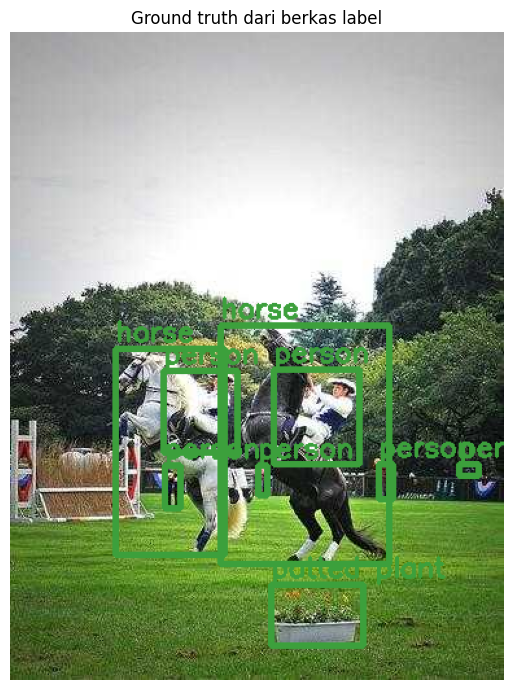

In [4]:
im = cv2.imread(p)
gambar = im.copy()
for c, (x1, y1, x2, y2) in zip(gt_kelas, gt_kotak.astype(int)):
    cv2.rectangle(gambar, (x1, y1), (x2, y2), (60, 160, 60), 3)
    cv2.putText(gambar, nama_kelas[c], (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (60, 160, 60), 2)
tampil([gambar], ["Ground truth dari berkas label"], ukuran=(9, 7))

> **Cek Pemahaman 1.** Sebuah citra berukuran lebar 640 dan tinggi 480 memiliki baris label `0 0.5 0.5 0.25 0.5`. Tentukan nilai (x1, y1, x2, y2) dalam satuan piksel.

<details><summary>Pembahasan</summary>

Pusat kotak adalah (0,5 × 640, 0,5 × 480) = (320, 240). Lebarnya 0,25 × 640 = 160 dan tingginya 0,5 × 480 = 240. Jadi, x1 = 320 − 80 = **240**, y1 = 240 − 120 = **120**, x2 = 320 + 80 = **400**, dan y2 = 240 + 120 = **360**.
</details>

## 2. Struktur *dataset* dan `data.yaml`
YOLO membaca *dataset* dari struktur folder berikut. Nama berkas citra dan berkas label harus sama persis.

```
dataset_kelompok/
├── images/train/  img001.jpg …      ├── labels/train/  img001.txt …
├── images/val/    img050.jpg …      ├── labels/val/    img050.txt …
└── data.yaml
```

In [5]:
from ultralytics.utils import ROOT
isi_yaml = [b for b in open(ROOT / "cfg" / "datasets" / "coco8.yaml").read().splitlines() if b and not b.startswith("#")]
print("\n".join(isi_yaml[:12]), "\n  ...")

path: coco8 # dataset root dir
train: images/train # train images (relative to 'path') 4 images
val: images/val # val images (relative to 'path') 4 images
test: # test images (optional)
names:
  0: person
  1: bicycle
  2: car
  3: motorcycle
  4: airplane
  5: bus
  6: train 
  ...


Berikut contoh `data.yaml` untuk kelompok dengan dua kelas. Sesuaikan isinya dengan topik Anda.

```yaml
path: /content/dataset_kelompok
train: images/train
val: images/val
names:
  0: botol_plastik
  1: kertas
```

## 3. Menganotasi data kelompok
Gunakan salah satu alat anotasi berikut, yaitu Label Studio, CVAT, Roboflow, atau makesense.ai, lalu **ekspor hasilnya dalam format YOLO**.

Pedoman anotasi:
1. Buat kotak yang **rapat** mengelilingi objek tanpa menyisakan latar berlebihan.
2. Labeli **semua** objek kelas target pada citra. Objek yang terlewat akan dihitung sebagai kesalahan model.
3. Jaga nama dan urutan kelas agar **konsisten** di seluruh *dataset* dan di `data.yaml`.
4. Sertakan variasi pencahayaan, sudut pengambilan, dan latar yang akan ditemui di lapangan.

Sel berikut membagi *dataset* menjadi data latih dan data validasi secara acak dengan perbandingan 80:20. Nilai *seed* dibuat tetap agar hasilnya dapat diulang. Di sini pembagian dicontohkan pada citra latih COCO8.

In [6]:
def bagi_dataset(folder_citra, tujuan, rasio_val=0.2, seed=42):
    citra = sorted(glob.glob(os.path.join(folder_citra, "*.jpg")))
    random.Random(seed).shuffle(citra)
    n_val = max(1, int(len(citra) * rasio_val))
    for bagian, daftar in [("val", citra[:n_val]), ("train", citra[n_val:])]:
        os.makedirs(os.path.join(tujuan, "images", bagian), exist_ok=True)
        os.makedirs(os.path.join(tujuan, "labels", bagian), exist_ok=True)
        for c in daftar:
            shutil.copy(c, os.path.join(tujuan, "images", bagian))
            if os.path.exists(path_label(c)):
                shutil.copy(path_label(c), os.path.join(tujuan, "labels", bagian))
    return len(citra) - n_val, n_val

n_train, n_val = bagi_dataset(os.path.join(akar, "images", "train"), "contoh_split")
print("latih:", n_train, "citra · validasi:", n_val, "citra")

latih: 3 citra · validasi: 1 citra


## 4. IoU antara dua kotak
Pada Minggu ke-12, IoU dihitung pada masker. Untuk kotak, rumusnya sama, yaitu **luas irisan dibagi luas gabungan**.

- Irisan dibatasi oleh x1 = max(x1ᴬ, x1ᴮ), y1 = max(y1ᴬ, y1ᴮ), x2 = min(x2ᴬ, x2ᴮ), dan y2 = min(y2ᴬ, y2ᴮ). Luasnya adalah max(0, x2 − x1) × max(0, y2 − y1).
- Luas gabungan adalah luas A + luas B − luas irisan.

In [7]:
def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    irisan = max(0, x2 - x1) * max(0, y2 - y1)
    gabungan = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - irisan
    return irisan / gabungan if gabungan > 0 else 0.0

A, B = [10, 10, 50, 50], [30, 30, 70, 70]
print("IoU contoh:", round(iou(A, B), 3))

IoU contoh: 0.143


> **Cek Pemahaman 2.** Hitunglah IoU kotak A = (10, 10, 50, 50) dan B = (30, 30, 70, 70) secara manual, lalu cocokkan dengan keluaran sel di atas.

<details><summary>Pembahasan</summary>

Irisan kedua kotak berada pada x = 30 sampai 50 dan y = 30 sampai 50 sehingga luasnya 20 × 20 = 400. Luas A = 40 × 40 = 1.600 dan luas B juga 1.600. Luas gabungan = 1.600 + 1.600 − 400 = 2.800. IoU = 400/2.800 = **0,143**. Walaupun kedua kotak tampak bertumpuk, IoU-nya rendah karena masing-masing hanya berbagi seperempat luasnya.
</details>

## 5. Mencocokkan prediksi dengan *ground truth*
Sebuah prediksi dihitung **benar (TP)** jika kelasnya sama dengan salah satu objek *ground truth* dan **IoU-nya mencapai ambang**, umumnya 0,5. Setiap objek *ground truth* hanya boleh dipasangkan satu kali, dan prediksi diproses mulai dari *confidence* tertinggi.

- Prediksi tanpa pasangan dihitung sebagai **FP** (deteksi palsu).
- Objek *ground truth* tanpa pasangan dihitung sebagai **FN** (objek terlewat).

In [8]:
def cocokkan(pred_kotak, pred_kelas, pred_conf, gt_kotak, gt_kelas, ambang=0.5):
    status, terpakai = {}, set()
    for i in np.argsort(-pred_conf):                       # confidence tertinggi lebih dulu
        terbaik, j_terbaik = 0.0, -1
        for j in range(len(gt_kotak)):
            if j in terpakai or gt_kelas[j] != pred_kelas[i]:
                continue
            nilai = iou(pred_kotak[i], gt_kotak[j])
            if nilai > terbaik:
                terbaik, j_terbaik = nilai, j
        if terbaik >= ambang:
            status[i] = "TP"
            terpakai.add(j_terbaik)
        else:
            status[i] = "FP"
    fn = [j for j in range(len(gt_kotak)) if j not in terpakai]
    return status, fn

r = model(p, conf=0.25, verbose=False)[0]
pk, pc, pf = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy()
status, fn = cocokkan(pk, pc, pf, gt_kotak, gt_kelas, ambang=0.5)
tp = sum(s == "TP" for s in status.values())
fp = sum(s == "FP" for s in status.values())
print(f"TP = {tp}, FP = {fp}, FN = {len(fn)}")
print(f"presisi = {tp / max(tp + fp, 1):.3f}, recall = {tp / max(tp + len(fn), 1):.3f}")

TP = 6, FP = 2, FN = 3
presisi = 0.750, recall = 0.667


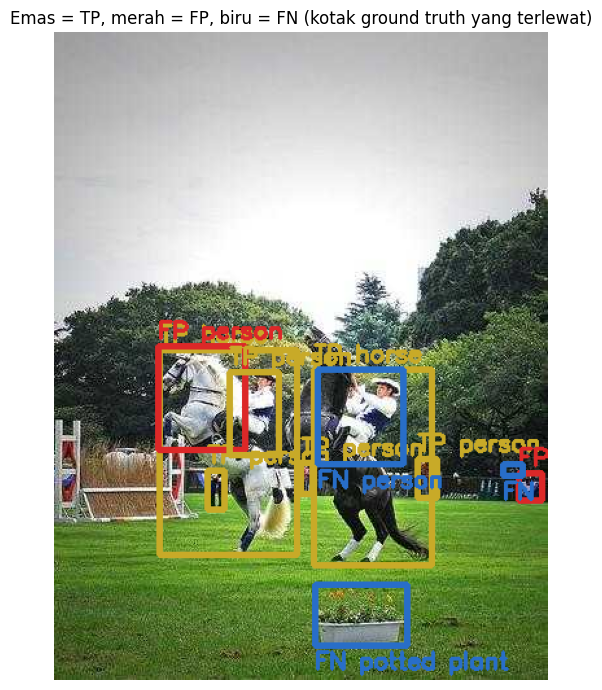

In [9]:
gambar = im.copy()
warna = {"TP": (40, 170, 200), "FP": (40, 40, 220)}
for i, (x1, y1, x2, y2) in enumerate(pk.astype(int)):
    cv2.rectangle(gambar, (x1, y1), (x2, y2), warna[status[i]], 3)
    cv2.putText(gambar, f"{status[i]} {nama_kelas[pc[i]]}", (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, warna[status[i]], 2)
for j in fn:
    x1, y1, x2, y2 = gt_kotak[j].astype(int)
    cv2.rectangle(gambar, (x1, y1), (x2, y2), (200, 110, 40), 3)
    cv2.putText(gambar, "FN " + nama_kelas[gt_kelas[j]], (x1, y2 + 18), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (200, 110, 40), 2)
tampil([gambar], ["Emas = TP, merah = FP, biru = FN (kotak ground truth yang terlewat)"], ukuran=(9, 7))

Ambang IoU yang lebih ketat menuntut kotak yang lebih tepat. Bandingkan hasilnya pada sel berikut.

In [10]:
for ambang in [0.5, 0.75, 0.9]:
    s, f = cocokkan(pk, pc, pf, gt_kotak, gt_kelas, ambang)
    tp = sum(v == "TP" for v in s.values())
    print(f"IoU ≥ {ambang}: TP = {tp}, FP = {len(s) - tp}, FN = {len(f)}")

IoU ≥ 0.5: TP = 6, FP = 2, FN = 3
IoU ≥ 0.75: TP = 2, FP = 6, FN = 7
IoU ≥ 0.9: TP = 0, FP = 8, FN = 9


> **Cek Pemahaman 3.** Mengapa jumlah TP berkurang ketika ambang IoU dinaikkan, padahal prediksinya sama?

<details><summary>Pembahasan</summary>

Prediksi yang posisinya sedikit bergeser masih memenuhi IoU ≥ 0,5, tetapi tidak memenuhi IoU ≥ 0,9. Prediksi itu berubah dari TP menjadi FP, dan objek *ground truth* pasangannya menjadi FN. Ambang yang lebih ketat menilai **ketepatan lokasi**, bukan hanya keberadaan objek.
</details>

## 6. Dari presisi dan *recall* ke mAP
Dengan menggeser ambang *confidence* dari tinggi ke rendah, kita memperoleh banyak pasangan presisi dan *recall* yang membentuk **kurva presisi-*recall***. Luas di bawah kurva untuk satu kelas disebut **AP** (*average precision*), sedangkan **mAP** adalah rata-rata AP dari semua kelas.

| Metrik | Arti |
|---|---|
| **mAP50** | mAP dengan ambang IoU 0,5 (deteksi dianggap cukup tepat) |
| **mAP50-95** | rata-rata mAP pada ambang IoU 0,50, 0,55, dan seterusnya sampai 0,95 (menuntut lokasi yang sangat tepat) |

Sel berikut menjalankan validasi YOLO pada data validasi COCO8.

In [11]:
hasil = model.val(data="coco8.yaml", imgsz=640, batch=4, plots=False, verbose=False)
print(f"presisi rata-rata : {hasil.box.mp:.3f}")
print(f"recall rata-rata  : {hasil.box.mr:.3f}")
print(f"mAP50             : {hasil.box.map50:.3f}")
print(f"mAP50-95          : {hasil.box.map:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 753.0±578.4 MB/s, size: 54.0 KB)
val: Scanning /content/datasets/coco8/labels/val... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.2Kit/s 0.0s
val: New cache created: /content/datasets/coco8/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.2it/s 0.2s
                   all          4         17       0.57       0.85      0.854      0.631
Speed: 0.7ms preprocess, 12.6ms inference, 0.0ms loss, 2.1ms postprocess per image
presisi rata-rata : 0.570
recall rata-rata  : 0.850
mAP50             : 0.854
mAP50-95          : 0.631


> **Cek Pemahaman 4.** Mengapa mAP50-95 selalu lebih kecil atau sama dengan mAP50? Metrik mana yang lebih tepat untuk topik *deteksi parkir kosong*?

<details><summary>Pembahasan</summary>

mAP50-95 merata-ratakan hasil pada ambang IoU yang makin ketat. Pada ambang 0,9 atau 0,95, sangat sedikit prediksi yang lolos sehingga rata-ratanya turun. Untuk parkir kosong, yang penting adalah ada atau tidaknya mobil di slot, bukan ketepatan kotak sampai beberapa piksel. Karena itu, **mAP50** yang dilengkapi presisi dan *recall* lebih bermakna. Laporkan keduanya, tetapi tafsirkan sesuai kebutuhan topik.
</details>

*Catatan:* COCO8 hanya berisi 4 citra validasi sehingga angka di atas hanya ilustrasi. Evaluasi tugas besar memerlukan data validasi kelompok yang jauh lebih banyak.

## 7. Daftar periksa *dataset* kelompok untuk Bagian C
- [ ] Kelas dan definisinya sudah ditetapkan dan ditulis di `data.yaml`.
- [ ] Citra dikumpulkan dalam kondisi yang bervariasi. Sebagai titik awal, usahakan sekitar 100 citra berlabel atau lebih untuk setiap kelas.
- [ ] Semua objek sudah dilabeli dengan kotak yang rapat dan diekspor dalam format YOLO.
- [ ] *Dataset* sudah dibagi menjadi data latih dan data validasi (misalnya 80:20) tanpa ada citra yang sama di kedua bagian.
- [ ] Sebagian citra validasi juga dipakai untuk mengevaluasi *baseline* klasik agar perbandingannya adil.

Catat kemajuan *dataset*, yaitu jumlah citra, jumlah label per kelas, dan alat anotasi yang dipakai, pada tab **Progres** di Daftar Kelompok.

## Ringkasan
- Label YOLO berisi satu baris untuk setiap objek dengan format `kelas xc yc w h` yang dinormalisasi.
- IoU kotak adalah luas irisan dibagi luas gabungan. Sebuah deteksi dianggap benar jika kelasnya sama dan IoU-nya mencapai ambang.
- Pencocokan prediksi menghasilkan TP, FP, dan FN sehingga presisi dan *recall* dapat dihitung persis seperti pada evaluasi segmentasi.
- mAP50 dan mAP50-95 merangkum kurva presisi-*recall*. Laporkan keduanya bersama presisi dan *recall*.

**Bagian C (Minggu ke-13)** membahas pelatihan ulang (*fine-tuning*) YOLO pada *dataset* kelompok dan perbandingannya dengan *baseline* klasik.

*Referensi:* J. Redmon dkk., “You Only Look Once: Unified, Real-Time Object Detection,” CVPR 2016 · M. Everingham dkk., “The PASCAL Visual Object Classes (VOC) Challenge,” IJCV, 2010 · T.-Y. Lin dkk., “Microsoft COCO: Common Objects in Context,” ECCV 2014 · Dokumentasi Ultralytics YOLO, docs.ultralytics.com.

## Bukti pengerjaan kelompok
Setelah semua sel di atas dijalankan, isi kelas dan nomor kelompok pada sel berikut, lalu jalankan sel tersebut. Sel ini merangkum hasil *notebook* Anda dalam satu baris. Salin baris itu ke tab **Progres** di Daftar Kelompok pada minggu berjalan.

Bukti ini dikumpulkan satu kali untuk setiap kelompok, tetapi pastikan setiap anggota sudah mencoba menjalankan *notebook* ini sendiri. Dosen dapat menanyakan isi *notebook* kepada anggota mana pun saat presentasi.

In [12]:
KELAS = "RA"      # isi RA atau RB
KELOMPOK = 8      # isi nomor kelompok Anda
JUMLAH_CITRA_BERLABEL = 0   # jumlah citra kelompok yang sudah dianotasi
ALAT_ANOTASI = ""           # misalnya Roboflow, Label Studio, CVAT, atau makesense.ai

from datetime import datetime
g = globals()
bagian = [f"[Notebook B] {KELAS}-{KELOMPOK:02d}"]
if "status" in g and "fn" in g:
    tp_b = sum(s == "TP" for s in status.values())
    bagian.append(f"COCO8 IoU 0,5: TP {tp_b}, FP {len(status) - tp_b}, FN {len(fn)}")
if "hasil" in g and hasattr(hasil, "box"):
    bagian.append(f"mAP50 COCO8 {hasil.box.map50:.3f}")
bagian.append(f"dataset kelompok: {JUMLAH_CITRA_BERLABEL} citra berlabel, alat: {ALAT_ANOTASI or 'belum diisi'}")
bagian.append(datetime.now().strftime("%d-%m-%Y %H:%M"))
if KELOMPOK == 0:
    print("Isi dulu KELAS, KELOMPOK, JUMLAH_CITRA_BERLABEL, dan ALAT_ANOTASI di atas, lalu jalankan ulang sel ini.")
print(" | ".join(bagian))

[Notebook B] RA-08 | COCO8 IoU 0,5: TP 6, FP 2, FN 3 | mAP50 COCO8 0.854 | dataset kelompok: 0 citra berlabel, alat: belum diisi | 22-11-2026 13:37
